# Data Science Nigeria (DSN) 2026 Hackathon 

This was my final notebook submitted for the hackathon


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import Ridge
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import cross_val_score, cross_val_predict, KFold, RandomizedSearchCV
from sklearn.metrics import root_mean_squared_error

pd.set_option("display.max_columns", 200)
sns.set_style("whitegrid")

RANDOM_STATE = 42

In [ ]:
train_df = pd.read_csv("train.csv") # Load the training data
test_df = pd.read_csv("test.csv") # Load the test data

In [ ]:
print(f"Train shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")
train_df.head()

Train shape: (6818, 13)
Test shape:  (1705, 12)


,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
0,row_00000,PRD-PRFP9S,14.252,Low Fat,0.0271,Frozen Foods,81.37,STORE-AGY,45,Large,Tier_3,Standard Supermarket,1764.98
1,row_00001,PRD-PXXK71,7.698,Low Fat,0.0720,HEALTH AND HYGIENE,42.05,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.13
2,row_00002,PRD-V5MOIJ,14.264,Regular,0.0421,Canned,41.35,STORE-89Z,33,Medium,Tier_1,Standard Supermarket,378.85
3,row_00003,PRD-UN5Z3J,NaN,Regular,0.0449,soft drinks,174.35,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,5595.72
4,row_00004,PRD-6RDQYB,10.338,Regular,0.0120,meat,203.06,STORE-9RG,28,Small,Tier_2,Standard Supermarket,2375.36


In [3]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6818 entries, 0 to 6817
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   6818 non-null   str    
 1   product_code         6818 non-null   str    
 2   product_weight_kg    5593 non-null   float64
 3   fat_content          6818 non-null   str    
 4   shelf_visibility     6818 non-null   float64
 5   product_category     6818 non-null   str    
 6   product_price        6818 non-null   float64
 7   store_code           6818 non-null   str    
 8   store_age_years      6818 non-null   int64  
 9   store_size           4899 non-null   str    
 10  store_location_tier  6818 non-null   str    
 11  store_format         6818 non-null   str    
 12  total_sales          6818 non-null   float64
dtypes: float64(4), int64(1), str(8)
memory usage: 692.6 KB


From the info, `product_weight_kg` and `store_size` have missing values. We have to handle these before training the model.

In [4]:
train_df.isnull().sum()

id                        0
product_code              0
product_weight_kg      1225
fat_content               0
shelf_visibility          0
product_category          0
product_price             0
store_code                0
store_age_years           0
store_size             1919
store_location_tier       0
store_format              0
total_sales               0
dtype: int64

In [5]:
train_df.describe()

,product_weight_kg,shelf_visibility,product_price,store_age_years,total_sales
count,5593.000000,6818.000000,6818.000000,6818.000000,6818.000000
mean,12.850876,0.065527,140.473623,34.178205,2174.756574
std,4.646542,0.051566,62.413513,8.384574,1697.894956
min,4.482000,0.000000,31.110000,23.000000,32.700000
25%,8.750000,0.026600,93.280000,28.000000,834.792500
50%,12.647000,0.053200,142.065000,33.000000,1790.890000
75%,16.894000,0.093400,185.987500,45.000000,3092.587500
max,21.883000,0.320100,273.040000,47.000000,12996.820000


## 3. Exploratory Data Analysis

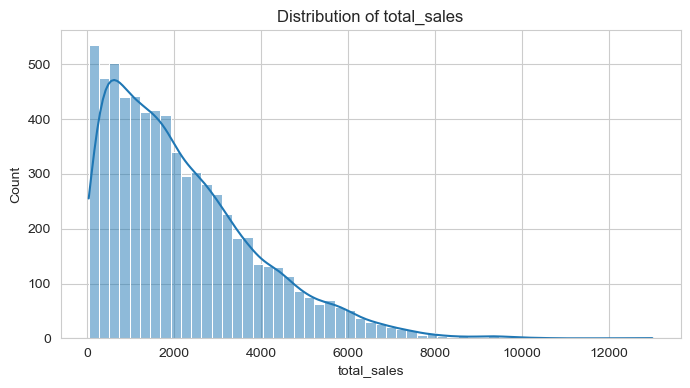

In [ ]:
# lets see what the target looks like

TARGET = "total_sales"

plt.figure(figsize=(8, 4))
sns.histplot(data=train_df, x=TARGET, kde=True)
plt.title("Distribution of total_sales")
plt.show()

The target (`total_sales`) is right-skewed. Most of the values are on the left (below 4000) and just a few high vakues.

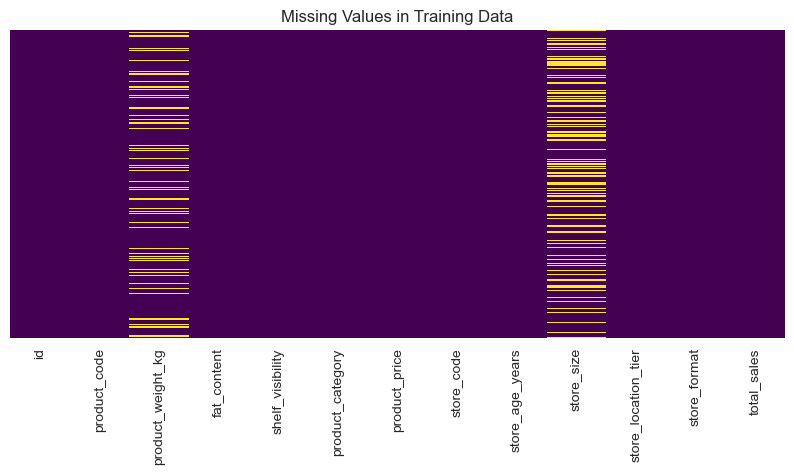

In [7]:
plt.figure(figsize=(10, 4))
sns.heatmap(train_df.isnull(), yticklabels=False, cbar=False, cmap="viridis")
plt.title("Missing Values in Training Data")
plt.show()

In [8]:
train_df["store_code"].value_counts()

store_code
STORE-YLW    754
STORE-9RG    752
STORE-AGY    748
STORE-7WS    748
STORE-OYG    744
STORE-HL7    742
STORE-DKU    736
STORE-89Z    728
STORE-JOR    439
STORE-T5G    427
Name: count, dtype: int64

In [ ]:
train_df.groupby("store_code")["store_size"].unique()
# Each store code has a unique store size.

In [ ]:
train_df.groupby("store_code")["store_location_tier"].unique()
# The result shows each store code has a unique store_location_tier. 

This means only 10 unique stores exist. 7 of them have known sizes while 3 do not.  
Also, each `store_code` has one `store_size`, one `store_format`, and one `store_location_tier`. Therefore, we can use those relationships to impute the missing `store_size` values.

In [ ]:
summary = (train_df.groupby("store_code").agg({
                "store_size": lambda x: x.unique().tolist(),
                "store_location_tier": lambda x: x.unique().tolist(),
                "store_format": lambda x: x.unique().tolist(),
                # The numeric column 
                TARGET: ["mean", "median"],
        }).reset_index()
)

# View the result
print(summary)


,store_code,store_size,store_location_tier,store_format,avg_sales
0,STORE-7WS,[Medium],[Tier_3],[Flagship Hypermarket],3660.182219
1,STORE-89Z,[Medium],[Tier_1],[Standard Supermarket],2365.926745
2,STORE-9RG,[Small],[Tier_2],[Standard Supermarket],2479.168098
3,STORE-AGY,[Large],[Tier_3],[Standard Supermarket],2254.890120
4,STORE-DKU,[nan],[Tier_2],[Standard Supermarket],2177.136481
5,STORE-HL7,[Medium],[Tier_3],[Superstore],1971.661954
6,STORE-JOR,[nan],[Tier_3],[Corner Shop],334.435011
7,STORE-OYG,[nan],[Tier_2],[Standard Supermarket],2365.833656
8,STORE-T5G,[Small],[Tier_1],[Corner Shop],338.326651
9,STORE-YLW,[Small],[Tier_1],[Standard Supermarket],2253.950690


From the above, a standard supermarket in Tier2 is likely "Small" in terms of Store_size.\
Which means TORE-DKU and STORE-OYG are Small since they fit that category. 
What's left is STORE-JOR which is a Corner Shop in Tier 3

From this table: `STORE-DKU` and `STORE-OYG` are Standard Supermarkets in Tier_2. The other Tier_2 Standard Supermarket (STORE-9RG) is "Small", so we impute them as **Small**.  

`STORE-JOR` is a Corner Shop in Tier_3 and its average sales are close to that of `STORE-T5G` (a Corner Shop in Tier_1, which is "Small". However, since there is no other corner shop in Tier_3 to compare with, we impute it using the mode for Tier_3, **Medium**.

In [ ]:
# Now for product_category

print(train_df["product_category"].value_counts())

Some of the values are recurring, but are in different cases and spelling  
Snack Foods vs snack foods  vs SNACK FOODS    
fruits and vegetables  vs FRUITS AND VEGETABLES  vs Fruits and Vegetables  
frozen foods vs Frozen Foods  vs   FROZEN FOODS   
dairy vs DAIRY  
Household vs HOUSEHOLD vs household  
Baking Goods vs BAKING GOODS  vs baking goods  
And then there's "Breads vs BREADS vs breads" in a separate category  
meat vs MEAT vs Meat  
hard drinks  vs HARD DRINKS   vs Hard Drinks  
canned vs CANNED   
SEAFOOD  vs seafood   
Soft Drinks vs    SOFT DRINKS     vs soft drinks  
canned vs CANNED  
Health and Hygiene    vs health and hygiene   vs HEALTH AND HYGIENE  
seafood vs SEAFOOD    vs Seafood     
Starchy Foods     vs STARCHY FOODS   vs starchy foods  
others vs Others  vs OTHERS                    
Breakfast     vs breakfast  

In [ ]:
# Now, let's see how the numerical features relate to total_sales

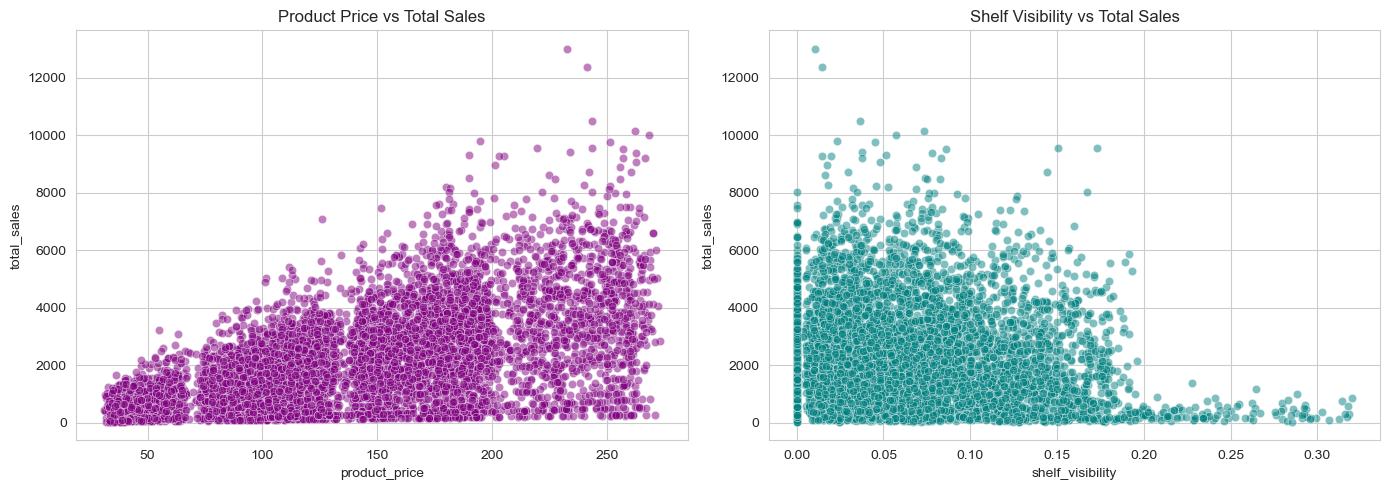

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x="product_price", y=TARGET, data=train_df, color="purple", alpha=0.5, ax=axes[0])
axes[0].set_title("Product Price vs Total Sales")

sns.scatterplot(x="shelf_visibility", y=TARGET, data=train_df, color="teal", alpha=0.5, ax=axes[1])
axes[1].set_title("Shelf Visibility vs Total Sales")
plt.tight_layout()
plt.show()

`product_price` has a positive relationship with `total_sales`.
While `shelf_visibility` shows a slightly negative relationship. Items with high visibility values (the ones nearer to 0) are likely those with prominent shelf placement, and they tend to sell more.

In [11]:
print("Rows with shelf_visibility == 0:", (train_df["shelf_visibility"] == 0).sum())
train_df[["product_weight_kg", "shelf_visibility", "product_price", "store_age_years", TARGET]].corr()

Rows with shelf_visibility == 0: 422


,product_weight_kg,shelf_visibility,product_price,store_age_years,total_sales
product_weight_kg,1.000000,-0.013986,0.034824,0.009020,0.015532
shelf_visibility,-0.013986,1.000000,0.003905,0.071078,-0.118124
product_price,0.034824,0.003905,1.000000,-0.012747,0.569833
store_age_years,0.009020,0.071078,-0.012747,1.000000,0.039443
total_sales,0.015532,-0.118124,0.569833,0.039443,1.000000


## 4. Feature Engineering

In [ ]:
# Let's build the pipeline
class StoreSizeImputer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        known = X.dropna(subset=["store_size"])
        self.store_map_ = known.groupby("store_code")["store_size"].agg(lambda s: s.mode().iloc[0]).to_dict()
        self.format_tier_map_ = (
            known.groupby(["store_format", "store_location_tier"])["store_size"]
            .agg(lambda s: s.mode().iloc[0])
            .to_dict()
        )
        self.global_mode_ = known["store_size"].mode().iloc[0]
        return self

    def transform(self, X):
        X = X.copy()

        def fill(row):
            if pd.notnull(row["store_size"]):
                return row["store_size"]
            if row["store_code"] in self.store_map_:
                return self.store_map_[row["store_code"]]
            key = (row["store_format"], row["store_location_tier"])
            return self.format_tier_map_.get(key, self.global_mode_)

        X["store_size"] = X.apply(fill, axis=1)
        return X

In [ ]:
# Now let's work on the missing values for product_weight-kg
class WeightImputer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.category_median_ = X.groupby("product_category")["product_weight_kg"].median()
        self.global_median_ = X["product_weight_kg"].median()
        return self

    def transform(self, X):
        X = X.copy()
        X["product_weight_kg"] = X["product_weight_kg"].fillna(
            X["product_category"].map(self.category_median_)
        )
        X["product_weight_kg"] = X["product_weight_kg"].fillna(self.global_median_)
        return X

In [ ]:
# for product_category's messy letter cassing
class VisibilityFixer(BaseEstimator, TransformerMixin):
  

    def fit(self, X, y=None):
        valid = X[X["shelf_visibility"] > 0]
        self.category_median_ = valid.groupby("product_category")["shelf_visibility"].median()
        self.global_median_ = valid["shelf_visibility"].median()
        return self

    def transform(self, X):
        X = X.copy()
        mask = X["shelf_visibility"] == 0
        fill_values = X.loc[mask, "product_category"].map(self.category_median_).fillna(self.global_median_)
        X.loc[mask, "shelf_visibility"] = fill_values
        return X


class VisibilityMeanRatio(BaseEstimator, TransformerMixin):


    def fit(self, X, y=None):
        self.category_mean_ = X.groupby("product_category")["shelf_visibility"].mean()
        self.global_mean_ = X["shelf_visibility"].mean()
        return self

    def transform(self, X):
        X = X.copy()
        cat_mean = X["product_category"].map(self.category_mean_).fillna(self.global_mean_)
        X["visibility_mean_ratio"] = X["shelf_visibility"] / cat_mean.replace(0, self.global_mean_)
        return X

In [ ]:

class CategoryAvgPriceFeature(BaseEstimator, TransformerMixin):
    

    def fit(self, X, y=None):
        self.category_avg_price_ = X.groupby("product_category")["product_price"].mean()
        self.global_avg_price_ = X["product_price"].mean()
        return self

    def transform(self, X):
        X = X.copy()
        cat_avg = X["product_category"].map(self.category_avg_price_).fillna(self.global_avg_price_)
        X["price_vs_category_avg"] = X["product_price"] / cat_avg
        return X

# Now we encode store_size and Store_location_tier
class FeatureCleaner(BaseEstimator, TransformerMixin):

    SIZE_MAPPING = {"small": 0, "medium": 1, "large": 2}
    TIER_MAPPING = {"tier_1": 0, "tier_2": 1, "tier_3": 2}

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X["product_category"] = X["product_category"].str.strip().str.lower()
        X["store_size_num"] = X["store_size"].str.strip().str.lower().map(self.SIZE_MAPPING)
        X["store_location_tier_num"] = X["store_location_tier"].str.strip().str.lower().map(self.TIER_MAPPING)
        return X

In [ ]:
# For the numeric features, there's no need to modify them or anything. 
# They just pass through the pipeline

numeric_features = [
    "product_weight_kg", "shelf_visibility", "product_price",
    "store_age_years", "store_size_num", "store_location_tier_num",
    "visibility_mean_ratio", "price_vs_category_avg",
]
categorical_features = ["store_format", "product_category"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical_features),
    ]
)

In [ ]:

def build_pipeline(model):
   
    return Pipeline(steps=[
        ("store_size_imputer", StoreSizeImputer()),
        ("weight_imputer", WeightImputer()),
        ("visibility_fixer", VisibilityFixer()),
        ("visibility_ratio", VisibilityMeanRatio()),
        ("price_ratio", CategoryAvgPriceFeature()),
        ("feature_cleaner", FeatureCleaner()),
        ("preprocessor", preprocessor),
        ("model", model),
    ])

# so whatever data we want to push into teh pipeline will run through these steps:
# 1. The store_size column gets encoded by the store_size_imputer 
# 2. The product_weight_kg gets encoded by the weight_imputer 
# 3. The store_size and store_location tier columns get encoded by the FeatureCleaner
# 4. The model runs on the data 


In [ ]:

def engineer_features(X_fit, X_apply):
    
    for step in [StoreSizeImputer(), WeightImputer(), VisibilityFixer(),
                 VisibilityMeanRatio(), CategoryAvgPriceFeature(), FeatureCleaner()]:
        X_fit = step.fit_transform(X_fit)
        X_apply = step.transform(X_apply)
    return X_fit, X_apply

### Preparing X and  y

In [ ]:
# Now, let's put X and y as these:
X = train_df.drop(columns=[TARGET, "id", "product_code", "fat_content"])
y = train_df[TARGET]

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 5. Comparison: Ridge vs Random Forest vs XGBoost

In [15]:
candidates = {
    "Ridge": build_pipeline(Ridge(alpha=1.0, random_state=RANDOM_STATE)),
    "RandomForest": build_pipeline(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    "XGBoost": build_pipeline(XGBRegressor(n_estimators=400, max_depth=8, learning_rate=0.1, random_state=RANDOM_STATE)),
}

results = []
for name, pipe in candidates.items():
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    rmse = -scores
    results.append({"model": name, "cv_rmse_mean": rmse.mean(), "cv_rmse_std": rmse.std()})
    print(f"{name:<15} RMSE = {rmse.mean():9.2f}  (+/- {rmse.std():.2f})")

pd.DataFrame(results).sort_values("cv_rmse_mean")

Ridge           RMSE =   1271.40  (+/- 27.20)
RandomForest    RMSE =   1122.63  (+/- 22.82)
XGBoost         RMSE =   1178.34  (+/- 22.01)


,model,cv_rmse_mean,cv_rmse_std
1,RandomForest,1122.629253,22.819161
2,XGBoost,1178.342069,22.007024
0,Ridge,1271.397786,27.202184


## 6. Hyperparameter Tuning

### Random Forest

In [16]:
rf_param_distributions = {
    "model__n_estimators": [200, 300, 500, 800],
    "model__max_depth": [None, 8, 12, 16, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", 0.5, 0.8],
}

rf_pipeline = build_pipeline(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))

rf_search = RandomizedSearchCV(
    rf_pipeline, param_distributions=rf_param_distributions, n_iter=30,
    scoring="neg_root_mean_squared_error", cv=cv, random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
rf_search.fit(X, y)

print("Best RF CV RMSE:", -rf_search.best_score_)
print("Best RF params:", rf_search.best_params_)

final_rf_pipeline = rf_search.best_estimator_

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best RF CV RMSE: 1081.6321070071685
Best RF params: {'model__n_estimators': 500, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_features': 'log2', 'model__max_depth': 8}


### XGBoost

In [17]:
xgb_param_distributions = {
    "model__n_estimators": [200, 300, 500, 800],
    "model__max_depth": [3, 5, 7, 10],
    "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "model__min_child_weight": [1, 5, 10],
    "model__subsample": [0.5, 0.8, 1.0],
    "model__colsample_bytree": [0.5, 0.8, 1.0],
}

xgb_pipeline = build_pipeline(XGBRegressor(objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1))

xgb_search = RandomizedSearchCV(
    xgb_pipeline, param_distributions=xgb_param_distributions, n_iter=30,
    scoring="neg_root_mean_squared_error", cv=cv, random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
xgb_search.fit(X, y)

print("Best XGBoost CV RMSE:", -xgb_search.best_score_)
print("Best XGBoost params:", xgb_search.best_params_)

final_xgb_pipeline = xgb_search.best_estimator_
best_xgb_params = {k.replace("model__", ""): v for k, v in xgb_search.best_params_.items()}

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best XGBoost CV RMSE: 1081.629630903263
Best XGBoost params: {'model__subsample': 1.0, 'model__n_estimators': 800, 'model__min_child_weight': 5, 'model__max_depth': 3, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.8}


### CatBoost

These params came from a small random search done in a previous cell

In [18]:
best_catboost_params = {
    "iterations": 1000,
    "depth": 4,
    "learning_rate": 0.01,
    "l2_leaf_reg": 1,
}

catboost_categorical_features = ["store_format", "product_category"]  # same as everyone else now

fold_rmses = []
for train_idx, val_idx in cv.split(X):
    X_train_cb, X_val_cb = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
    y_train_cb, y_val_cb = y.iloc[train_idx], y.iloc[val_idx]

    X_train_cb, X_val_cb = engineer_features(X_train_cb, X_val_cb)
    for col in catboost_categorical_features:
        X_train_cb[col] = X_train_cb[col].astype(str).str.strip().str.lower()
        X_val_cb[col] = X_val_cb[col].astype(str).str.strip().str.lower()

    model = CatBoostRegressor(**best_catboost_params, loss_function="RMSE",
                               random_seed=RANDOM_STATE, verbose=0, thread_count=-1)
    model.fit(X_train_cb[numeric_features + catboost_categorical_features], y_train_cb,
              cat_features=catboost_categorical_features)

    preds = model.predict(X_val_cb[numeric_features + catboost_categorical_features])
    fold_rmses.append(root_mean_squared_error(y_val_cb, preds))

print("CatBoost CV RMSE:", sum(fold_rmses) / len(fold_rmses))

CatBoost CV RMSE: 1076.685242672935


## 7. Stacking: Ridge Meta-Model on XGBoost + CatBoost



In [19]:
oof_xgb = np.zeros(len(X))
oof_catboost = np.zeros(len(X))
y_arr = y.values

for train_idx, val_idx in cv.split(X):
    X_tr, X_val = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
    y_tr = y_arr[train_idx]

    xgb_fold = build_pipeline(XGBRegressor(**best_xgb_params, random_state=RANDOM_STATE, n_jobs=-1))
    xgb_fold.fit(X_tr, y_tr)
    oof_xgb[val_idx] = xgb_fold.predict(X_val)

    X_tr_cb, X_val_cb = engineer_features(X_tr.copy(), X_val.copy())
    for col in catboost_categorical_features:
        X_tr_cb[col] = X_tr_cb[col].astype(str).str.strip().str.lower()
        X_val_cb[col] = X_val_cb[col].astype(str).str.strip().str.lower()

    cb_fold = CatBoostRegressor(**best_catboost_params, loss_function="RMSE",
                                 random_seed=RANDOM_STATE, verbose=0, thread_count=-1)
    cb_fold.fit(X_tr_cb[numeric_features + catboost_categorical_features], y_tr,
                cat_features=catboost_categorical_features)
    oof_catboost[val_idx] = cb_fold.predict(X_val_cb[numeric_features + catboost_categorical_features])

meta_X = np.column_stack([oof_xgb, oof_catboost])
meta_model = Ridge(alpha=1.0)
meta_model.fit(meta_X, y_arr)

meta_preds_oof = meta_model.predict(meta_X)
print("Learned weights:", meta_model.coef_, "intercept:", meta_model.intercept_)
print("Stacked (Ridge meta-model) OOF RMSE:", root_mean_squared_error(y_arr, meta_preds_oof))
print("Correlation between XGBoost and CatBoost OOF predictions:", np.corrcoef(oof_xgb, oof_catboost)[0, 1])

Learned weights: [-0.05310566  1.05119186] intercept: -4.514319858898489
Stacked (Ridge meta-model) OOF RMSE: 1076.8894709013416
Correlation between XGBoost and CatBoost OOF predictions: 0.9972426680420677


## 8. Other Things I Tried 

- Random Forest as a third blend member
- LightGBM as a third stacked model: It correlated too highly with XGBoost/CatBoost
- Capping extreme target values during training: It was worse. Not used.


## 9. Final Fit on All Training Data

In [20]:
final_xgb_pipeline = build_pipeline(XGBRegressor(**best_xgb_params, random_state=RANDOM_STATE, n_jobs=-1))
final_xgb_pipeline.fit(X, y)
xgb_test_preds = final_xgb_pipeline.predict(test_df)

In [21]:
X_test_cb = test_df.drop(columns=["id", "product_code", "fat_content"]).copy()
X_train_full_cb, X_test_cb = engineer_features(X.copy(), X_test_cb)

for col in catboost_categorical_features:
    X_train_full_cb[col] = X_train_full_cb[col].astype(str).str.strip().str.lower()
    X_test_cb[col] = X_test_cb[col].astype(str).str.strip().str.lower()

final_catboost_model = CatBoostRegressor(**best_catboost_params, loss_function="RMSE",
                                          random_seed=RANDOM_STATE, verbose=0, thread_count=-1)
final_catboost_model.fit(X_train_full_cb[numeric_features + catboost_categorical_features], y,
                          cat_features=catboost_categorical_features)

catboost_test_preds = final_catboost_model.predict(X_test_cb[numeric_features + catboost_categorical_features])

## 10. Final Submission

In [22]:
final_test_meta_X = np.column_stack([xgb_test_preds, catboost_test_preds])
final_blended_preds = meta_model.predict(final_test_meta_X)

submission = pd.DataFrame({
    "id": test_df["id"],
    "total_sales": final_blended_preds
})
submission.to_csv("submission_stacked.csv", index=False)
submission.head()

,id,total_sales
0,row_00009,2733.364083
1,row_00015,4180.313184
2,row_00019,3115.229269
3,row_00020,3182.769859
4,row_00023,2576.634896
